# PumpCast : exploration des données

Avant de construire le modèle, je veux comprendre comment les prix bougent vraiment.
Les questions auxquelles ce notebook doit répondre :

1. À quoi ressemblent les données (volume, période, carburants) ?
2. Comment le prix à la pompe suit le pétrole, et **avec combien de jours de retard** ?
3. À quelle fréquence une station change son prix, et de combien ?
4. Y a-t-il un jour de la semaine où le plein est moins cher ?
5. Est-ce que les vacances scolaires font monter les prix ?
6. Les stations d'autoroute sont-elles plus chères, et une station plus chère que son département a-t-elle tendance à baisser ?
7. Quel score doit battre le modèle (la baseline "le prix ne bouge pas") ?

Données : historique des stations d'Auvergne-Rhône-Alpes (2023 à aujourd'hui), moyennes par département pour toute la France, Brent, EUR/USD et calendrier.

In [1]:
import sys
sys.path.insert(0, "..")  # pour importer le package pumpcast_ml depuis le dossier notebooks

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pumpcast_ml import data
from pumpcast_ml.db import get_db

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

db = get_db()
stations = data.load_stations(db)
market = data.load_market(db)
cal = data.load_calendar(db)
gazole = data.load_prices(db, "GAZOLE")
dep_gaz = data.load_department_daily(db, "GAZOLE")
print(f"{len(gazole):,} relevés gazole, {gazole.station_id.nunique()} stations, du {gazole.date.min():%d/%m/%Y} au {gazole.date.max():%d/%m/%Y}")

1,744,467 relevés gazole, 1502 stations, du 01/01/2023 au 04/11/2026


## 1. Les données

Nombre de relevés et de stations par carburant dans l'historique AURA.

In [2]:
overview = pd.DataFrame(list(db["prices"].aggregate([
    {"$group": {"_id": "$meta.fuel", "releves": {"$sum": 1}, "stations": {"$addToSet": "$meta.station_id"}}},
    {"$project": {"releves": 1, "stations": {"$size": "$stations"}}},
    {"$sort": {"releves": -1}},
]))).rename(columns={"_id": "carburant"})
overview

,carburant,releves,stations
0,GAZOLE,1744467,1502
1,SP98,1367945,1230
2,E10,1298808,1216
3,SP95,634290,707
4,E85,537271,585
5,GPLC,169069,224


Le gazole, l'E10 et le SP98 sont les carburants les plus vendus. Le SP95 recule (remplacé par l'E10), l'E85 et le GPL ne sont vendus que dans une partie des stations.
Pour la suite de l'exploration je me concentre sur le **gazole**, le carburant le plus répandu.

## 2. Évolution des prix et lien avec le pétrole

Le prix moyen national se calcule à partir des moyennes par département, pondérées par le nombre de stations.
Le Brent est converti en euros par litre (prix du baril / taux EUR/USD / 159 litres) pour être comparable au prix à la pompe.

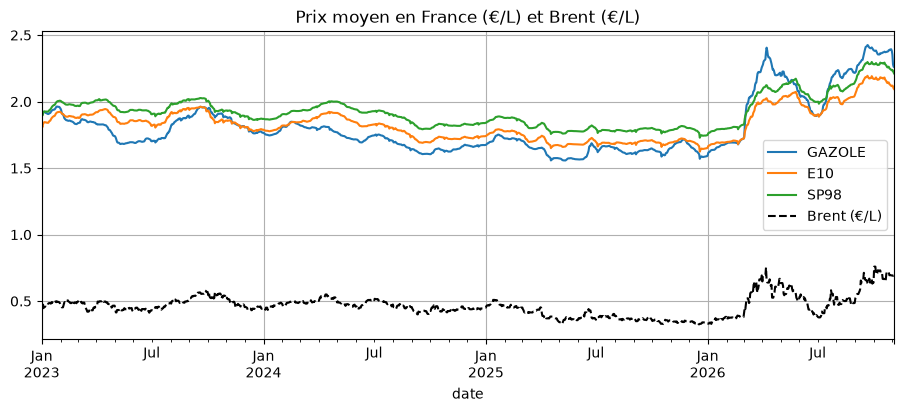

,GAZOLE,brent_eur_l,ecart_gazole_brent
date,,,
2023-01-31,1.932,0.483,1.449
2023-04-30,1.806,0.484,1.321
2023-07-31,1.726,0.455,1.271
2023-10-31,1.909,0.542,1.366
2024-01-31,1.761,0.462,1.299
2024-04-30,1.797,0.528,1.268
2024-07-31,1.734,0.494,1.239
2024-10-31,1.631,0.438,1.193
2025-01-31,1.719,0.481,1.238


In [3]:
def national_average(dep: pd.DataFrame) -> pd.Series:
    w = dep.assign(total=dep.avg_price * dep.station_count).groupby("date")[["total", "station_count"]].sum()
    return w.total / w.station_count

nat = pd.DataFrame({fuel: national_average(data.load_department_daily(db, fuel)) for fuel in ["GAZOLE", "E10", "SP98"]})
nat = nat.join(market.set_index("date")["brent_eur_l"], how="left")

ax = nat[["GAZOLE", "E10", "SP98"]].plot(title="Prix moyen en France (€/L) et Brent (€/L)")
nat["brent_eur_l"].plot(ax=ax, color="black", linestyle="--", label="Brent (€/L)")
ax.legend()
plt.show()

monthly = nat.resample("ME").mean()
monthly["ecart_gazole_brent"] = monthly["GAZOLE"] - monthly["brent_eur_l"]
monthly[["GAZOLE", "brent_eur_l", "ecart_gazole_brent"]].iloc[::3]

**Ce qu'on voit.** Les trois carburants suivent la même tendance. De 2023 à fin 2025, les prix baissent doucement (le gazole passe de 1,93 € à environ 1,62 €) avec un Brent stable entre 0,35 et 0,55 €/L. Début mars 2026, tout s'emballe : le Brent passe de 0,36 à plus de 0,70 €/L et le gazole dépasse 2,30 €, au point de devenir plus cher que le SP98.

L'écart entre la pompe et le Brent (taxes, raffinage, transport, marge) était stable autour de 1,20 à 1,30 € jusqu'en 2025. Il monte à 1,60-1,67 € en 2026 : le gazole a augmenté plus vite que le pétrole brut.

**Pour le modèle :** 2026 ne ressemble pas aux années d'avant. Il faudra regarder les scores à part sur 2026, car un modèle entraîné sur 2023-2025 risque de mal gérer cette période.

## 3. Avec combien de retard la pompe suit le pétrole ?

Idée : si le Brent monte un jour, on regarde de combien le prix moyen à la pompe bouge les jours suivants.

**Corrélation** : un nombre entre -1 et 1 qui dit si deux séries bougent ensemble (1 = toujours dans le même sens, 0 = aucun lien).
On calcule la corrélation entre la variation du prix à la pompe sur 7 jours et la variation du Brent sur 7 jours **décalée de k jours** dans le passé.
Le décalage qui donne la plus forte corrélation est le délai de réaction des stations.

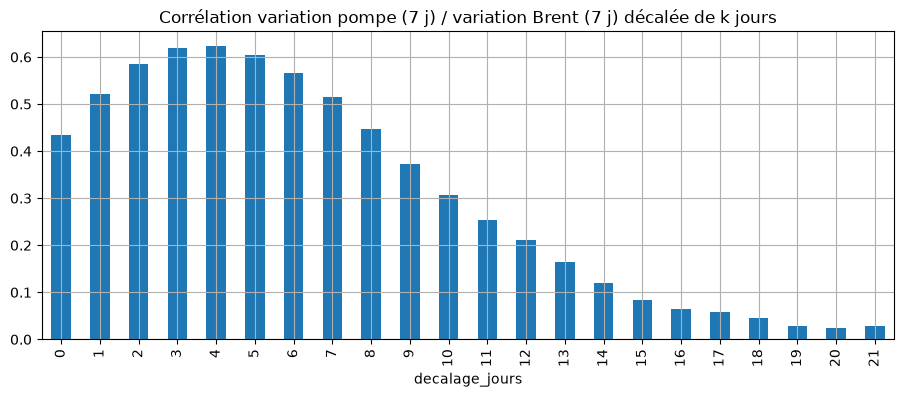

Corrélation maximale avec un décalage de 4 jours (0.62), sans décalage : 0.44


In [4]:
s = nat[["GAZOLE", "brent_eur_l"]].dropna()
pump7 = s.GAZOLE.diff(7)
corr = pd.Series({k: pump7.corr(s.brent_eur_l.diff(7).shift(k)) for k in range(0, 22)}, name="correlation")
corr.index.name = "decalage_jours"

corr.plot(kind="bar", title="Corrélation variation pompe (7 j) / variation Brent (7 j) décalée de k jours")
plt.show()
print(f"Corrélation maximale avec un décalage de {corr.idxmax()} jours ({corr.max():.2f}), sans décalage : {corr[0]:.2f}")

**Le délai est net.** La corrélation passe de 0,44 sans décalage à 0,62 avec 4 jours de décalage. Le prix à la pompe réagit donc au pétrole avec quelques jours de retard. C'est exactement ce que le modèle peut exploiter : une hausse du Brent cette semaine annonce une hausse à la pompe la semaine suivante.

Pour aller plus loin qu'une corrélation, une régression linéaire **à retards distribués** : la variation du jour à la pompe est expliquée par les variations du Brent des 21 derniers jours.
Chaque coefficient dit quelle part d'une hausse du Brent arrive à la pompe k jours plus tard. La somme cumulée montre la vitesse de transmission.

On sépare aussi les hausses et les baisses du Brent : on dit souvent que les prix montent "comme une fusée" et descendent "comme une plume".

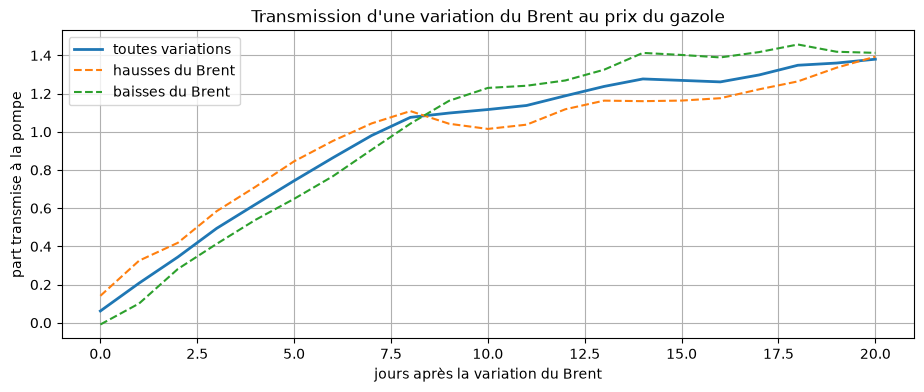

Transmission totale après 20 jours : 1.38 (1 € de plus par litre de Brent = 1.38 € de plus à la pompe)
50 % transmis après 5 jours, 90 % après 14 jours
Hausses : 1.39 transmis, dont 0.95 en une semaine
Baisses : 1.41 transmis, dont 0.77 en une semaine


In [5]:
d_pump = s.GAZOLE.diff()
d_brent = s.brent_eur_l.diff()
LAGS = 21

def lagged(x: pd.Series, name: str) -> pd.DataFrame:
    return pd.concat({f"{name}_{k}": x.shift(k) for k in range(LAGS)}, axis=1)

# Modèle 1 : hausses et baisses ensemble
X = lagged(d_brent, "b")
ok = X.notna().all(axis=1) & d_pump.notna()
beta, *_ = np.linalg.lstsq(X[ok].values, d_pump[ok].values, rcond=None)
cumul = pd.Series(np.cumsum(beta), name="transmission cumulée")

# Modèle 2 : hausses et baisses séparées
X2 = pd.concat([lagged(d_brent.clip(lower=0), "up"), lagged(d_brent.clip(upper=0), "down")], axis=1)
ok2 = X2.notna().all(axis=1) & d_pump.notna()
beta2, *_ = np.linalg.lstsq(X2[ok2].values, d_pump[ok2].values, rcond=None)
up_cumul, down_cumul = np.cumsum(beta2[:LAGS]), np.cumsum(beta2[LAGS:])

fig, ax = plt.subplots()
ax.plot(cumul.values, label="toutes variations", linewidth=2)
ax.plot(up_cumul, label="hausses du Brent", linestyle="--")
ax.plot(down_cumul, label="baisses du Brent", linestyle="--")
ax.set_xlabel("jours après la variation du Brent")
ax.set_ylabel("part transmise à la pompe")
ax.set_title("Transmission d'une variation du Brent au prix du gazole")
ax.legend()
plt.show()

total = cumul.iloc[-1]
half = int(np.argmax(cumul.values >= total / 2))
ninety = int(np.argmax(cumul.values >= 0.9 * total))
print(f"Transmission totale après {LAGS - 1} jours : {total:.2f} (1 € de plus par litre de Brent = {total:.2f} € de plus à la pompe)")
print(f"50 % transmis après {half} jours, 90 % après {ninety} jours")
print(f"Hausses : {up_cumul[-1]:.2f} transmis, dont {up_cumul[6]:.2f} en une semaine")
print(f"Baisses : {down_cumul[-1]:.2f} transmis, dont {down_cumul[6]:.2f} en une semaine")

**La moitié d'une variation du Brent arrive à la pompe en 5 jours, 90 % en 14 jours.**

La transmission totale (1,38) dépasse 1, et c'est normal : la TVA de 20 % s'applique sur le prix hors taxes, donc 1 € de plus en amont fait déjà 1,20 € à la pompe. En plus, sur la période, le gazole raffiné a monté plus que le brut.

Au final, hausses et baisses sont transmises au même niveau (1,39 et 1,41), mais **les hausses arrivent plus vite** : au bout d'une semaine, 0,95 sur 1,39 est déjà passé pour une hausse (68 %), contre 0,77 sur 1,41 pour une baisse (55 %). L'effet « fusée et plume » existe, surtout sur la vitesse.

**Pour le modèle :** les variations du Brent décalées de 0 à 14 jours, et ses variations sur 7 et 14 jours, sont les variables les plus prometteuses.

## 4. À quelle fréquence une station change son prix ?

C'est la question la plus importante pour le modèle : si les prix ne bougent presque jamais d'un jour à l'autre, "le prix ne bouge pas" sera une baseline très difficile à battre à J+1.

Part des jours où le prix change : 24.3%
Une station change son prix en moyenne tous les 4.1 jours
Par station : médiane 20.8% des jours, 10 % des stations à moins de 7.2%, 10 % à plus de 43.0%
Taille d'un changement : médiane 1.2 centimes, 90 % sous 5.2 centimes
Hausses : 49.3% des changements


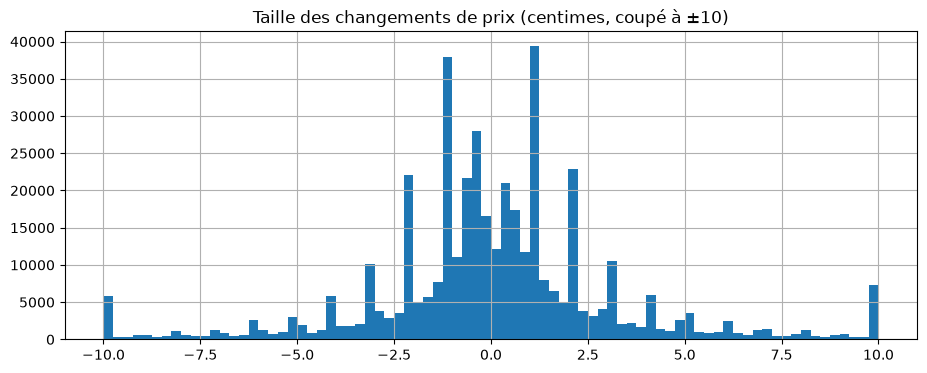

In [6]:
g = gazole.copy()
g["prev_price"] = g.groupby("station_id", observed=True).price.shift()
g["prev_date"] = g.groupby("station_id", observed=True).date.shift()
consecutive = g[(g.date - g.prev_date) == pd.Timedelta(days=1)].copy()
consecutive["change_cts"] = (consecutive.price - consecutive.prev_price) * 100
changes = consecutive[consecutive.change_cts.abs() > 0.05]

share_changed = len(changes) / len(consecutive)
per_station = consecutive.groupby("station_id", observed=True).change_cts.apply(lambda c: (c.abs() > 0.05).mean())
print(f"Part des jours où le prix change : {share_changed:.1%}")
print(f"Une station change son prix en moyenne tous les {1 / share_changed:.1f} jours")
print(f"Par station : médiane {per_station.median():.1%} des jours, 10 % des stations à moins de {per_station.quantile(0.1):.1%}, 10 % à plus de {per_station.quantile(0.9):.1%}")
print(f"Taille d'un changement : médiane {changes.change_cts.abs().median():.1f} centimes, 90 % sous {changes.change_cts.abs().quantile(0.9):.1f} centimes")
print(f"Hausses : {(changes.change_cts > 0).mean():.1%} des changements")

changes.change_cts.clip(-10, 10).hist(bins=80)
plt.title("Taille des changements de prix (centimes, coupé à ±10)")
plt.show()

In [7]:
by_road = consecutive.merge(stations[["station_id", "road_type"]], on="station_id")
by_road.groupby("road_type").change_cts.apply(lambda c: (c.abs() > 0.05).mean()).rename("part des jours avec changement")

road_type
A   0.282
R   0.241
Name: part des jours avec changement, dtype: float64

**Une station change son prix environ un jour sur quatre, et souvent de peu** (1,2 centime en médiane). Les comportements varient beaucoup : 10 % des stations changent plus de 4 jours sur 10, 10 % moins d'une fois tous les 14 jours. Les hausses et les baisses sont aussi fréquentes. Les stations d'autoroute changent un peu plus souvent (28 % des jours contre 24 %).

**Pour le modèle :** la fréquence de changement propre à chaque station et le nombre de jours depuis le dernier changement sont des variables utiles.

## 5. Y a-t-il un jour moins cher ?

Pour chaque station et chaque semaine, on calcule l'écart entre le prix du jour et le prix moyen de la station cette semaine-là.
Comme ça on enlève l'effet de la tendance (pétrole qui monte ou baisse) et les différences entre stations. On regarde aussi quels jours les stations changent leurs prix.

In [8]:
w = gazole.copy()
w["week"] = w.date.dt.to_period("W")
w["weekday"] = w.date.dt.day_of_week
w["ecart_cts"] = (w.price - w.groupby(["station_id", "week"], observed=True).price.transform("mean")) * 100
jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

table = pd.DataFrame({
    "ecart_moyen_cts": w.groupby("weekday").ecart_cts.mean(),
    "part_des_changements": changes.date.dt.day_of_week.value_counts(normalize=True).sort_index(),
    "part_des_hausses": changes[changes.change_cts > 0].date.dt.day_of_week.value_counts(normalize=True).sort_index(),
    "part_des_baisses": changes[changes.change_cts < 0].date.dt.day_of_week.value_counts(normalize=True).sort_index(),
})
table.index = jours
table

,ecart_moyen_cts,part_des_changements,part_des_hausses,part_des_baisses
lundi,-0.098,0.138,0.149,0.127
mardi,0.019,0.184,0.196,0.172
mercredi,0.072,0.172,0.171,0.173
jeudi,0.085,0.170,0.168,0.171
vendredi,-0.085,0.220,0.195,0.244
samedi,-0.008,0.107,0.107,0.107
dimanche,0.015,0.010,0.013,0.007


**Il n'y a pas de jour moins cher qui vaille le coup.** Les écarts sont de l'ordre de 0,1 centime, soit 5 centimes sur un plein de 50 litres. Le conseil « faire le plein le lundi » qu'on lit parfois ne se vérifie pas ici.

En revanche, les stations changent leurs prix surtout en semaine : presque jamais le dimanche (1 % des changements), et le vendredi est le jour des baisses (24 % des baisses).

**Pour l'appli :** la fonctionnalité « jour le moins cher » devra dire honnêtement que l'écart est négligeable.

**Pour le modèle :** le jour de la semaine compte pour savoir si un changement est probable (pas le dimanche), pas pour le niveau du prix.

## 6. Vacances scolaires

Les stations d'AURA sont en zone A (académies de Lyon, Grenoble et Clermont-Ferrand).
On regarde l'évolution du prix moyen AURA autour du premier jour de chaque période de vacances de la zone A (de 14 jours avant à 14 jours après), comparée à une évolution "normale" sur n'importe quelle période de même durée.
On le fait à part pour les stations d'autoroute, qui sont celles où l'effet devrait se voir.

23 débuts de vacances zone A dans la période


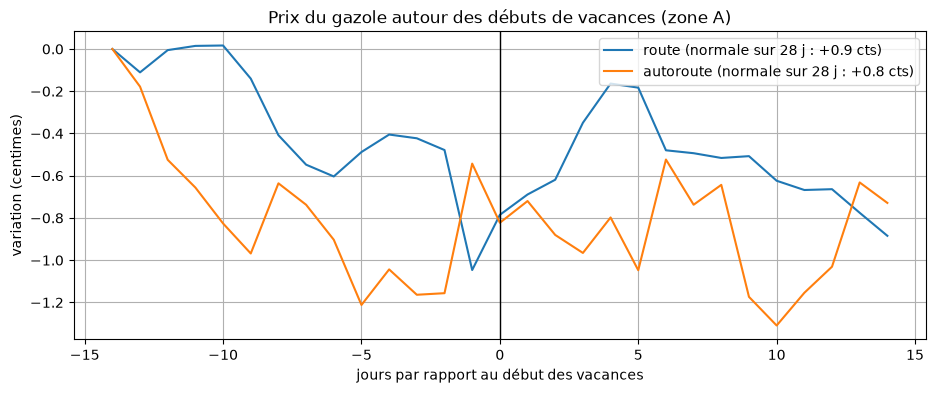

In [9]:
AURA = ["01", "03", "07", "15", "26", "38", "42", "43", "63", "69", "73", "74"]
g2 = gazole.merge(stations[["station_id", "road_type"]], on="station_id")
series = {
    "route": g2[g2.road_type == "R"].groupby("date").price.mean(),
    "autoroute": g2[g2.road_type == "A"].groupby("date").price.mean(),
}

calendar_a = cal.set_index("date").vacation_a
starts = calendar_a[(calendar_a) & (~calendar_a.shift(1, fill_value=False))].index
starts = [d for d in starts if gazole.date.min() + pd.Timedelta(days=14) <= d <= gazole.date.max() - pd.Timedelta(days=14)]
print(f"{len(starts)} débuts de vacances zone A dans la période")

window = range(-14, 15)
fig, ax = plt.subplots()
for name, sr in series.items():
    paths = []
    for d0 in starts:
        base = sr.get(d0 - pd.Timedelta(days=14))
        path = [sr.get(d0 + pd.Timedelta(days=k)) for k in window]
        if base is not None and None not in path:
            paths.append((np.array(path) - base) * 100)
    mean_path = np.mean(paths, axis=0)
    # Évolution normale sur 28 jours, toutes périodes confondues
    normal = (sr.shift(-28) - sr).mean() * 100
    ax.plot(list(window), mean_path, label=f"{name} (normale sur 28 j : {normal:+.1f} cts)")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("jours par rapport au début des vacances")
ax.set_ylabel("variation (centimes)")
ax.set_title("Prix du gazole autour des débuts de vacances (zone A)")
ax.legend()
plt.show()

**Pas d'effet visible des vacances.** Autour des débuts de vacances, le prix moyen bouge de moins d'un centime, et plutôt à la baisse, alors qu'il monte de 0,8 à 0,9 centime sur une période normale de 28 jours. Même sur autoroute, il n'y a pas de hausse avant les départs. Avec seulement 23 débuts de vacances, la courbe est bruitée et on ne peut pas non plus conclure à une baisse.

**Pour le modèle :** je garde les variables de vacances, car le modèle saura les ignorer si elles ne servent à rien et la permutation importance le confirmera. Mais je ne m'attends pas à ce qu'elles aident.

## 7. Autoroute et écart à la moyenne du département

In [10]:
daily_type = g2.groupby(["date", "road_type"]).price.mean().unstack()
gap_cts = (daily_type["A"] - daily_type["R"]) * 100
print(f"Une station d'autoroute est en moyenne {gap_cts.mean():.1f} centimes plus chère (de {gap_cts.quantile(0.1):.1f} à {gap_cts.quantile(0.9):.1f} selon les jours)")

Une station d'autoroute est en moyenne 17.6 centimes plus chère (de 13.4 à 21.0 selon les jours)


Une station d'autoroute coûte 17,6 centimes de plus, soit environ 9 € sur un plein de 50 litres. Le type de station doit donc faire partie des variables.

Une station plus chère que la moyenne de son département a-t-elle tendance à baisser ? Si oui, l'écart à la moyenne du département est une bonne variable pour le modèle.
On compare l'écart du jour avec la variation de prix de la station sur les 7 jours suivants.

In [11]:
m = gazole.merge(stations[["station_id", "department", "road_type"]], on="station_id")
m = m.merge(dep_gaz[["date", "department", "avg_price"]], on=["date", "department"])
m["ecart_dep_cts"] = (m.price - m.avg_price) * 100

pivot = gazole.pivot(index="date", columns="station_id", values="price")
future7 = ((pivot.shift(-7) - pivot) * 100).stack().dropna().rename("variation_7j_cts").reset_index()
m = m.merge(future7, on=["date", "station_id"])
m = m[m.road_type == "R"]  # l'autoroute fausserait la comparaison (toujours au-dessus)

bins = [-np.inf, -10, -5, -2, 2, 5, 10, np.inf]
labels = ["< -10", "-10 à -5", "-5 à -2", "-2 à +2", "+2 à +5", "+5 à +10", "> +10"]
m["tranche"] = pd.cut(m.ecart_dep_cts, bins=bins, labels=labels)
print(f"Corrélation écart au département / variation à 7 jours : {m.ecart_dep_cts.corr(m.variation_7j_cts):.2f}")
m.groupby("tranche", observed=True).agg(nb=("variation_7j_cts", "size"), variation_7j_moyenne_cts=("variation_7j_cts", "mean"))

Corrélation écart au département / variation à 7 jours : -0.16


,nb,variation_7j_moyenne_cts
tranche,,
< -10,32426,4.544
-10 à -5,387820,0.813
-5 à -2,448231,0.259
-2 à +2,282436,-0.146
+2 à +5,191247,-0.254
+5 à +10,200089,-0.267
> +10,69242,-1.461


**Oui, et c'est net : les stations reviennent vers la moyenne de leur département.** Une station plus de 10 centimes au-dessus de son département baisse en moyenne de 1,5 centime dans la semaine. Une station plus de 10 centimes en dessous remonte de 4,5 centimes.

L'effet est plus fort du côté « trop bas » : une station très en dessous est souvent une station qui n'a pas encore suivi une hausse générale.

La corrélation seule (-0,16) n'est pas énorme, parce que la plupart des stations sont proches de la moyenne. C'est sur les cas extrêmes que l'écart au département est utile.

## 8. La baseline à battre

La baseline naïve dit "le prix dans h jours = le prix d'aujourd'hui". Son erreur est la variation réelle du prix.

**MAE** (erreur absolue moyenne) : la moyenne des écarts entre prédiction et réalité, en valeur absolue. Une MAE de 1,5 centime veut dire qu'on se trompe en moyenne de 1,5 centime.

In [12]:
rows = []
for h in range(1, 8):
    # dropna : avec pandas 3, stack() garde les cases vides (station sans prix ce jour-là)
    delta = ((pivot.shift(-h) - pivot) * 100).stack().dropna()
    rows.append({"horizon_jours": h, "mae_baseline_cts": delta.abs().mean(), "part_sans_changement": (delta.abs() < 0.05).mean(),
                 "part_variation_2cts_ou_plus": (delta.abs() >= 2).mean()})
baseline = pd.DataFrame(rows).set_index("horizon_jours")
baseline

,mae_baseline_cts,part_sans_changement,part_variation_2cts_ou_plus
horizon_jours,,,
1,0.556,0.757,0.097
2,1.033,0.600,0.183
3,1.462,0.478,0.259
4,1.822,0.394,0.323
5,2.143,0.332,0.380
6,2.445,0.283,0.430
7,2.730,0.245,0.474


In [13]:
# Même chose par année : la difficulté dépend beaucoup de l'agitation du marché
delta7 = ((pivot.shift(-7) - pivot) * 100)
delta7.groupby(delta7.index.year).apply(lambda x: x.stack().dropna().abs().mean()).rename("mae_baseline_j7_cts")

date
2023   2.436
2024   1.560
2025   2.026
2026   5.393
Name: mae_baseline_j7_cts, dtype: float64

**À J+1, la baseline est déjà très bonne.** 76 % des stations ont exactement le même prix le lendemain, et l'erreur moyenne n'est que de 0,56 centime.

**À J+7, c'est beaucoup plus dur** : 2,7 centimes d'erreur, et 47 % des stations bougent d'au moins 2 centimes.

La recommandation se joue sur 3 jours avec un seuil de 2 centimes. Ça ne concerne que 26 % des cas : dans environ 3 cas sur 4, la bonne réponse sera « prix stable ».

L'erreur dépend énormément de la période : 1,6 centime à J+7 en 2024, contre 5,4 en 2026. Comparer le modèle à la baseline n'a donc de sens que sur la même période de test, et c'est ce que prévoit l'évaluation.

## Bilan pour la construction du modèle

**Variables qui devraient compter :**
- la variation du Brent en euros par litre, avec 0 à 14 jours de retard (la moitié de l'effet arrive en 5 jours) ;
- l'écart entre la station et la moyenne de son département (les stations reviennent vers la moyenne) ;
- la fréquence de changement de la station et le nombre de jours depuis son dernier changement ;
- le type de station (17,6 centimes de plus sur autoroute) ;
- le jour de la semaine, pour la probabilité qu'un changement ait lieu (presque jamais le dimanche).

**Variables probablement faibles :** vacances scolaires et jours fériés. Je les garde pour que le modèle tranche lui-même.

**Points d'attention :**
- La baseline est très forte à court terme (76 % de prix inchangés à J+1). Il est réaliste que le modèle ne la batte pas sur les premiers horizons. Dans ce cas, la règle d'honnêteté s'applique : pas de recommandation sur ces horizons.
- 2026 est une période agitée, très différente de 2023-2025. Les scores doivent être donnés par période, et la période de test doit inclure 2026.
- Plutôt que le Brent et l'EUR/USD séparés, le Brent converti en euros par litre est la variable qui a du sens économiquement. On garde quand même les deux.